In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

np.random.seed(42)
n_samples = 1000

data = pd.DataFrame({
    'CustomerID': range(1001, 1001 + n_samples),
    'Age': np.random.randint(18, 70, size=n_samples),
    'Tenure_Months': np.random.randint(1, 60, size=n_samples),
    'Monthly_Spend': np.round(np.random.uniform(20.0, 200.0, size=n_samples), 2),
    'Support_Tickets': np.random.poisson(lam=2, size=n_samples),
    'Discount_Usage': np.random.choice([0, 1], size=n_samples, p=[0.4, 0.6]),
    'Satisfaction_Score': np.random.randint(1, 6, size=n_samples)
})

churn_prob = (
    (data['Satisfaction_Score'] <= 2).astype(int) * 0.4 +
    (data['Support_Tickets'] > 3).astype(int) * 0.3 +
    (data['Tenure_Months'] < 6).astype(int) * 0.2
)
data['Churn'] = (churn_prob + np.random.normal(0, 0.1, n_samples) > 0.4).astype(int)

print(data.head())
print(data.info())
print(data.isnull().sum().sum())

   CustomerID  Age  Tenure_Months  Monthly_Spend  Support_Tickets  \
0        1001   56             35         196.61                0   
1        1002   69             51         133.73                2   
2        1003   46             15          66.76                3   
3        1004   32             25         134.12                2   
4        1005   60             55         117.20                0   

   Discount_Usage  Satisfaction_Score  Churn  
0               0                   3      0  
1               1                   2      1  
2               1                   3      0  
3               1                   4      0  
4               0                   4      0  
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerID          1000 non-null   int64  
 1   Age                 1000 non-null   int32  
 2   Tenure_M

C:\Users\kabir\AppData\Local\Temp\ipykernel_29912\576163472.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Churn', palette='coolwarm')


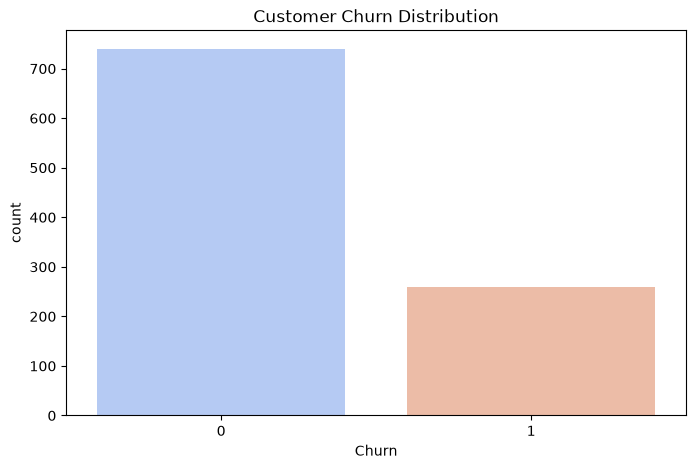

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='Churn', palette='coolwarm')
plt.title('Customer Churn Distribution')
plt.show()


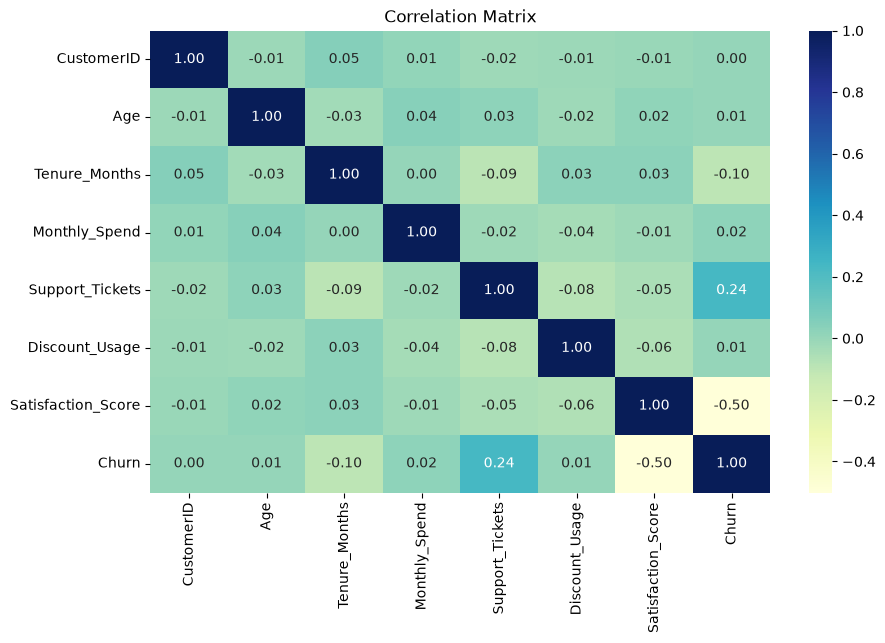

In [9]:
plt.figure(figsize=(10, 6))
sns.heatmap(data.corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       143
           1       0.64      0.56      0.60        57

    accuracy                           0.79       200
   macro avg       0.74      0.72      0.73       200
weighted avg       0.78      0.79      0.78       200

0.8840019629493313


C:\Users\kabir\AppData\Local\Temp\ipykernel_29912\2098427048.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance, x='Importance', y='Feature', palette='viridis')


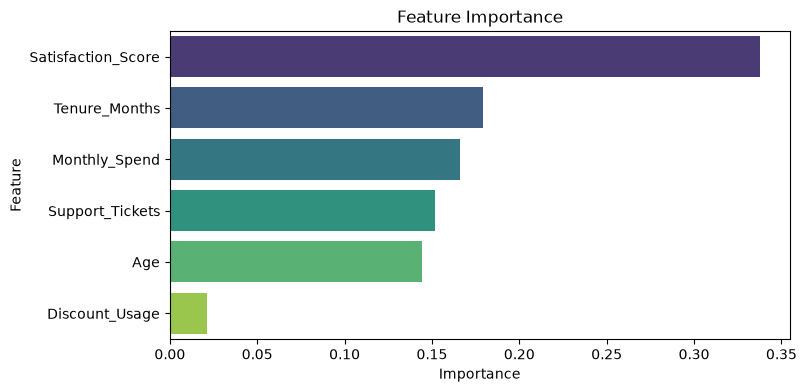

In [10]:
X = data.drop(columns=['CustomerID', 'Churn'])
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(classification_report(y_test, y_pred))
print(roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:,1]))

importance = pd.DataFrame({'Feature': X.columns, 'Importance': model.feature_importances_}).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(data=importance, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance')
plt.show()